# 09 SHAPによる影響方向確認と明示ルール候補

08の比較で、XGBoostは固定したR2ルールを満たす候補になりました。このNotebookでは、XGBoostに対してSHAPを使い、重要特徴量が予測値を上げる方向か下げる方向かを確認します。

確認すること:

- SHAPで重要特徴量の影響方向を見る
- XGBoostの外れ配合を再確認する
- データから読み取れる明示ルール候補を整理する


In [1]:
import os
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/plastech_matplotlib_cache")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display

from plastech.modeling import DEFAULT_TARGET, evaluate_model_random_split, group_labels

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["font.family"] = ["Hiragino Sans", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


Matplotlib is building the font cache; this may take a moment.


/Users/otsukamashu/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## XGBoostモデルを作成する

通常ランダム分割で学習し、予測値・外れ配合・特徴量重要度を確認します。


In [2]:
xgb_eval = evaluate_model_random_split(
    model_name="xgboost",
    dataset_name="processed_main",
    target_col=DEFAULT_TARGET,
    n_estimators=600,
    random_state=42,
)

display(xgb_eval.metrics)
display(xgb_eval.feature_importance[["display_name", "importance"]].head(20))


,model,evaluation,rows,MAE,RMSE,R2,max_abs_error
0,xgboost,random_split,786,1.780334,2.58867,0.761975,20.235276


,display_name,importance
113,フタル酸エステル系 / DINP (可塑剤オイル類.30),0.036629
35,架橋PVC800 / GR800T (PVC.52),0.033966
112,フタル酸エステル系 / DOP (可塑剤オイル類.29),0.033553
109,トリメリット酸系 / モノサイザW750 (可塑剤オイル類.25),0.028711
22,PVC700 / TH700(BK) (PVC.35),0.021208
66,未処理重質炭カル / NS400 (充填剤.2),0.020751
86,表面処理重質炭カル / NCC410 (充填剤.28),0.019529
152,Ba系複合安定剤 / アデカAC216 (安定剤金属石鹸.14),0.017093
340,ホウ酸亜鉛 / アルカネックスFRC500 (難燃剤.12),0.016768
108,トリメリット酸系 / TOTM (可塑剤オイル類.24),0.016719


## SHAP値を計算する

SHAPは計算が重いため、全件ではなくサンプルで傾向を確認します。ここでは最大800件を使います。


In [3]:
X = xgb_eval.prepared.X
sample_size = min(800, len(X))
X_sample = X.sample(n=sample_size, random_state=42)

explainer = shap.TreeExplainer(xgb_eval.model)
shap_values = explainer.shap_values(X_sample)

print("sample_size:", sample_size)
print("shap_values shape:", shap_values.shape)


sample_size: 800
shap_values shape: (800, 342)


## SHAP重要度と影響方向

`mean_abs_shap` は予測への影響の大きさです。`value_shap_corr` は、特徴量の値が大きいとSHAP値が上がるか下がるかの単純な方向ヒントです。

- 正: 値が大きいほど予測値を上げる傾向
- 負: 値が大きいほど予測値を下げる傾向
- 弱い: 単純な一方向では説明しにくい


In [4]:
metadata = xgb_eval.feature_importance.set_index("column")[["base_group", "category", "label", "display_name"]]

shap_summary_rows = []
for i, column in enumerate(X_sample.columns):
    values = X_sample[column]
    shap_col = shap_values[:, i]
    corr = pd.Series(values).corr(pd.Series(shap_col)) if values.nunique(dropna=True) > 1 else np.nan
    if pd.isna(corr):
        direction = "判定保留"
    elif corr > 0.1:
        direction = "値が大きいほど予測値を上げる傾向"
    elif corr < -0.1:
        direction = "値が大きいほど予測値を下げる傾向"
    else:
        direction = "単純方向は弱い"
    shap_summary_rows.append({
        "column": column,
        "display_name": metadata.at[column, "display_name"],
        "base_group": metadata.at[column, "base_group"],
        "category": metadata.at[column, "category"],
        "label": metadata.at[column, "label"],
        "mean_abs_shap": float(np.abs(shap_col).mean()),
        "mean_shap": float(shap_col.mean()),
        "value_shap_corr": corr,
        "shap_direction_hint": direction,
        "nonzero_rate_in_sample": float((values != 0).mean()),
    })

shap_summary = pd.DataFrame(shap_summary_rows).sort_values("mean_abs_shap", ascending=False)
display(shap_summary.head(30))


/Users/otsukamashu/Library/Python/3.9/lib/python/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/otsukamashu/Library/Python/3.9/lib/python/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,column,display_name,base_group,category,label,mean_abs_shap,mean_shap,value_shap_corr,shap_direction_hint,nonzero_rate_in_sample
112,可塑剤オイル類.29,フタル酸エステル系 / DOP (可塑剤オイル類.29),可塑剤オイル類,フタル酸エステル系,DOP,2.286071,-0.108137,0.001480,単純方向は弱い,0.48000
113,可塑剤オイル類.30,フタル酸エステル系 / DINP (可塑剤オイル類.30),可塑剤オイル類,フタル酸エステル系,DINP,1.677329,0.047661,-0.021102,単純方向は弱い,0.35000
66,充填剤.2,未処理重質炭カル / NS400 (充填剤.2),充填剤,未処理重質炭カル,NS400,1.180441,-0.063955,-0.023765,単純方向は弱い,0.51750
12,PVC.23,PVC1300 / TH1300(JG) (PVC.23),PVC,PVC1300,TH1300(JG),0.441587,-0.000130,-0.024438,単純方向は弱い,0.32875
108,可塑剤オイル類.24,トリメリット酸系 / TOTM (可塑剤オイル類.24),可塑剤オイル類,トリメリット酸系,TOTM,0.375157,0.034107,-0.055074,単純方向は弱い,0.13250
23,PVC.38,PVC800 / TH800(DJ) (PVC.38),PVC,PVC800,TH800(DJ),0.320337,-0.009218,0.013373,単純方向は弱い,0.07000
18,PVC.30,PVC2000 / TH2000(SW) (PVC.30),PVC,PVC2000,TH2000(SW),0.252562,0.022326,0.061221,単純方向は弱い,0.08250
10,PVC.15,PVC1000 / TH1000(GW) (PVC.15),PVC,PVC1000,TH1000(GW),0.250281,0.009615,-0.051394,単純方向は弱い,0.22875
22,PVC.35,PVC700 / TH700(BK) (PVC.35),PVC,PVC700,TH700(BK),0.226341,0.011187,0.020697,単純方向は弱い,0.03250
114,可塑剤オイル類.31,フタル酸エステル系 / DIDP (可塑剤オイル類.31),可塑剤オイル類,フタル酸エステル系,DIDP,0.217390,0.031147,-0.148659,値が大きいほど予測値を下げる傾向,0.04375


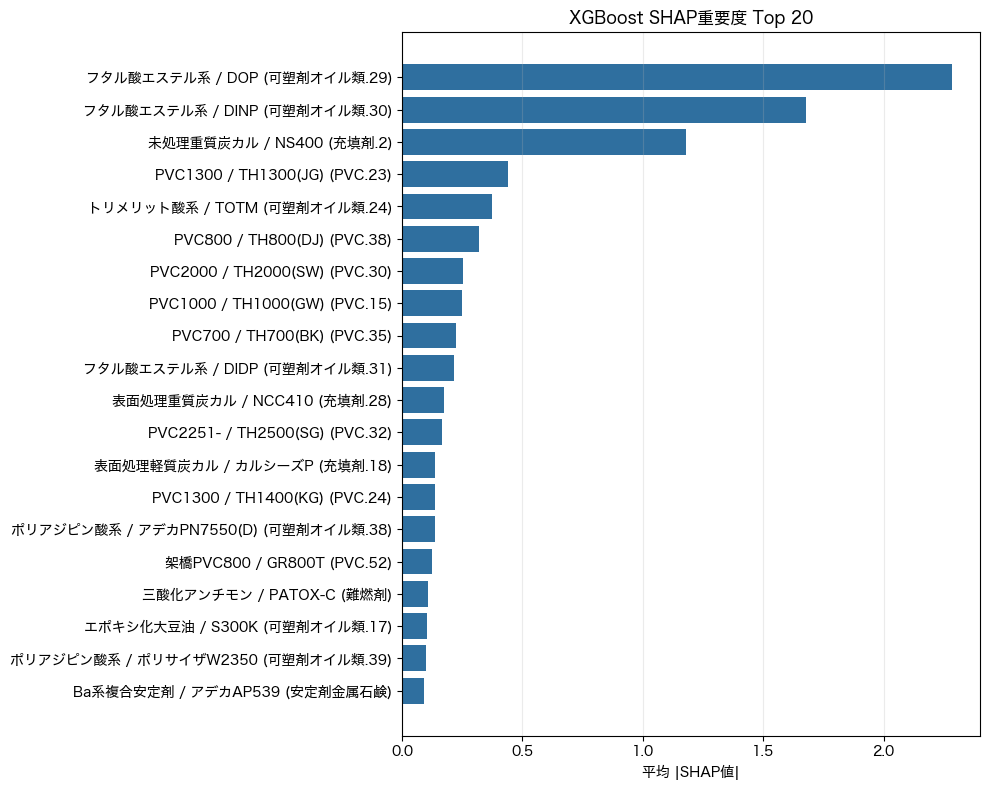

In [5]:
plot_df = shap_summary.head(20).sort_values("mean_abs_shap")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_df["display_name"], plot_df["mean_abs_shap"], color="#2f6f9f")
ax.set_xlabel("平均 |SHAP値|")
ax.set_title("XGBoost SHAP重要度 Top 20")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


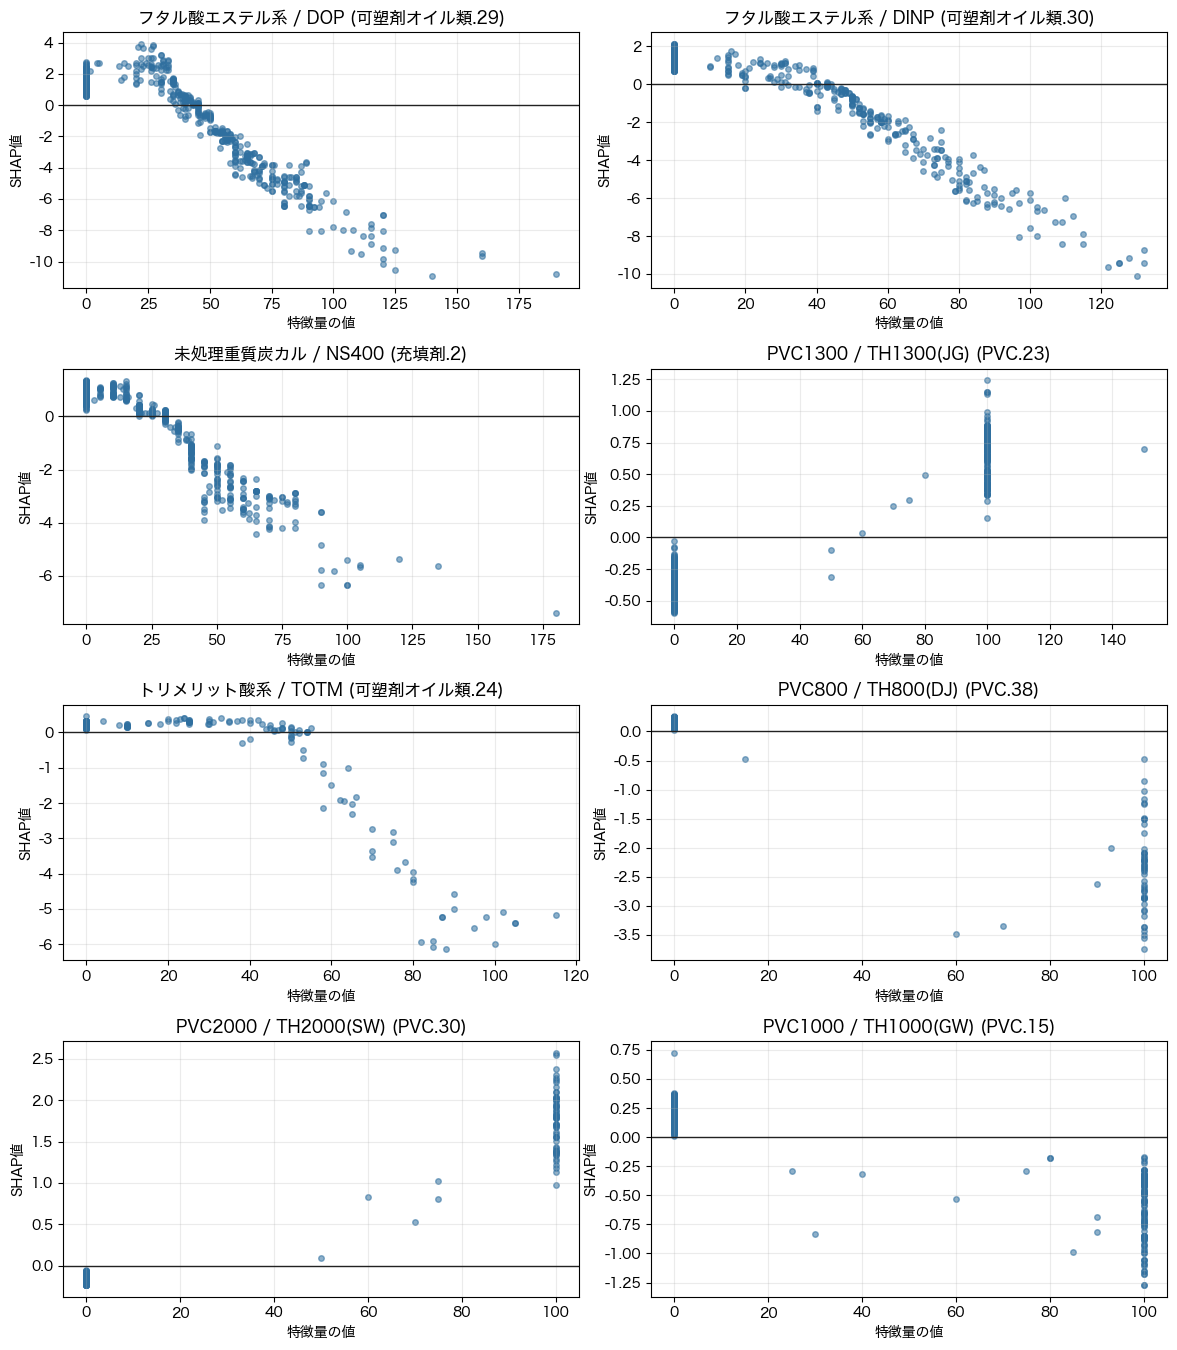

In [6]:
top_cols = shap_summary.head(8)["column"].tolist()
cols = 2
rows = int(np.ceil(len(top_cols) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 3.4))
axes = np.array(axes).ravel()

for ax, column in zip(axes, top_cols):
    idx = list(X_sample.columns).index(column)
    ax.scatter(X_sample[column], shap_values[:, idx], s=16, alpha=0.55, color="#2f6f9f")
    ax.axhline(0, color="#222222", linewidth=1)
    ax.set_title(metadata.at[column, "display_name"])
    ax.set_xlabel("特徴量の値")
    ax.set_ylabel("SHAP値")
    ax.grid(alpha=0.25)

for ax in axes[len(top_cols):]:
    ax.axis("off")

fig.tight_layout()
plt.show()


## 外れ配合を再確認する

XGBoostで外れが大きい配合を、主PVC・主可塑剤・上位SHAP特徴量と一緒に確認します。


In [7]:
predictions = xgb_eval.predictions.copy()
prepared = xgb_eval.prepared
primary_pvc = group_labels(prepared, "primary_pvc")
primary_plasticizer = group_labels(prepared, "primary_plasticizer")

outliers = predictions.head(30).copy()
outliers["primary_pvc"] = primary_pvc.loc[outliers.index].values
outliers["primary_plasticizer"] = primary_plasticizer.loc[outliers.index].values

for column in shap_summary.head(10)["column"]:
    outliers[metadata.at[column, "display_name"]] = prepared.X.loc[outliers.index, column].values

display(outliers)


,row_id,actual,predicted,error,abs_error,primary_pvc,primary_plasticizer,フタル酸エステル系 / DOP (可塑剤オイル類.29),フタル酸エステル系 / DINP (可塑剤オイル類.30),未処理重質炭カル / NS400 (充填剤.2),PVC1300 / TH1300(JG) (PVC.23),トリメリット酸系 / TOTM (可塑剤オイル類.24),PVC800 / TH800(DJ) (PVC.38),PVC2000 / TH2000(SW) (PVC.30),PVC1000 / TH1000(GW) (PVC.15),PVC700 / TH700(BK) (PVC.35),フタル酸エステル系 / DIDP (可塑剤オイル類.31)
783,CP0000000000993,2.6,22.835276,20.235276,20.235276,PVC1000 / TH1000(GW) (PVC.15),フタル酸エステル系 / DINP (可塑剤オイル類.30),0.0,40.0,5.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
2761,CP0000000003370,6.7,20.442089,13.742089,13.742089,PVC1000 / TH1000(GW) (PVC.15),エポキシ化大豆油 / S300K (可塑剤オイル類.17),1.5,0.0,0.0,0.0,0.0,0.0,0.0,40.0,0.0,0.0
4522,CP1000000007609,11.3,22.533798,11.233798,11.233798,PVC-650 / TH500(MG) (PVC.41),フタル酸エステル系 / DINP (可塑剤オイル類.30),0.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3004,CP0000000003854,13.9,24.550291,10.650291,10.650291,E・PVC2251- / TE2800 (PVC.13),ポリアジピン酸系 / アデカPN310 (可塑剤オイル類.53),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4365,CP1000000006749,34.3,24.603554,-9.696446,9.696446,PVC1000 / TH1000(GW) (PVC.15),エポキシ化大豆油 / S300K (可塑剤オイル類.17),5.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
2898,CP0000000003648,13.4,22.745781,9.345781,9.345781,(no PVC),(no 可塑剤オイル類),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2893,CP0000000003639,14.0,23.089882,9.089882,9.089882,(no PVC),(no 可塑剤オイル類),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4703,CP1000000008325,32.0,23.398094,-8.601906,8.601906,PVC1000 / TH1000(GW) (PVC.15),エポキシ化大豆油 / S300K (可塑剤オイル類.17),0.0,0.0,25.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
1482,CP0000000001947,31.9,23.346695,-8.553305,8.553305,PVC2251- / TH2500(SG) (PVC.32),フタル酸エステル系 / DOP (可塑剤オイル類.29),36.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1616,CP0000000002101,33.3,24.949875,-8.350125,8.350125,PVC2000 / TH2000(SW) (PVC.30),ポリアジピン酸系 / ポリサイザW2050 (可塑剤オイル類.41),0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0


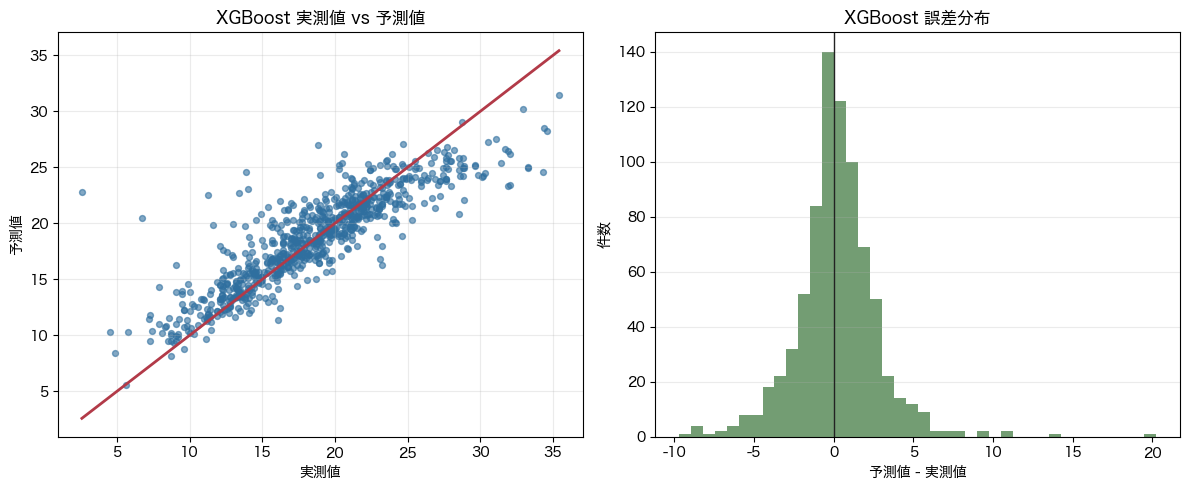

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(predictions["actual"], predictions["predicted"], s=18, alpha=0.6, color="#2f6f9f")
min_value = min(predictions["actual"].min(), predictions["predicted"].min())
max_value = max(predictions["actual"].max(), predictions["predicted"].max())
ax.plot([min_value, max_value], [min_value, max_value], color="#b23a48", linewidth=2)
ax.set_xlabel("実測値")
ax.set_ylabel("予測値")
ax.set_title("XGBoost 実測値 vs 予測値")
ax.grid(alpha=0.25)

ax = axes[1]
ax.hist(predictions["error"], bins=40, color="#5b8c5a", alpha=0.85)
ax.axvline(0, color="#222222", linewidth=1)
ax.set_xlabel("予測値 - 実測値")
ax.set_ylabel("件数")
ax.set_title("XGBoost 誤差分布")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


## 明示的なルール候補に整理する

これは最終ルールではなく、SHAPとデータ傾向から作る候補です。材料知識で妥当性を確認してから採用します。


In [9]:
rule_candidates = shap_summary.head(15).copy()
rule_candidates["candidate_rule"] = rule_candidates.apply(
    lambda row: f"{row['display_name']} は、{row['shap_direction_hint']}。材料知識で確認する。",
    axis=1,
)
rule_candidates["status"] = "材料知識で要確認"

display(rule_candidates[[
    "display_name",
    "mean_abs_shap",
    "value_shap_corr",
    "shap_direction_hint",
    "nonzero_rate_in_sample",
    "candidate_rule",
    "status",
]])


,display_name,mean_abs_shap,value_shap_corr,shap_direction_hint,nonzero_rate_in_sample,candidate_rule,status
112,フタル酸エステル系 / DOP (可塑剤オイル類.29),2.286071,0.001480,単純方向は弱い,0.48000,フタル酸エステル系 / DOP (可塑剤オイル類.29) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
113,フタル酸エステル系 / DINP (可塑剤オイル類.30),1.677329,-0.021102,単純方向は弱い,0.35000,フタル酸エステル系 / DINP (可塑剤オイル類.30) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
66,未処理重質炭カル / NS400 (充填剤.2),1.180441,-0.023765,単純方向は弱い,0.51750,未処理重質炭カル / NS400 (充填剤.2) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
12,PVC1300 / TH1300(JG) (PVC.23),0.441587,-0.024438,単純方向は弱い,0.32875,PVC1300 / TH1300(JG) (PVC.23) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
108,トリメリット酸系 / TOTM (可塑剤オイル類.24),0.375157,-0.055074,単純方向は弱い,0.13250,トリメリット酸系 / TOTM (可塑剤オイル類.24) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
23,PVC800 / TH800(DJ) (PVC.38),0.320337,0.013373,単純方向は弱い,0.07000,PVC800 / TH800(DJ) (PVC.38) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
18,PVC2000 / TH2000(SW) (PVC.30),0.252562,0.061221,単純方向は弱い,0.08250,PVC2000 / TH2000(SW) (PVC.30) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
10,PVC1000 / TH1000(GW) (PVC.15),0.250281,-0.051394,単純方向は弱い,0.22875,PVC1000 / TH1000(GW) (PVC.15) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
22,PVC700 / TH700(BK) (PVC.35),0.226341,0.020697,単純方向は弱い,0.03250,PVC700 / TH700(BK) (PVC.35) は、単純方向は弱い。材料知識で確認する。,材料知識で要確認
114,フタル酸エステル系 / DIDP (可塑剤オイル類.31),0.217390,-0.148659,値が大きいほど予測値を下げる傾向,0.04375,フタル酸エステル系 / DIDP (可塑剤オイル類.31) は、値が大きいほど予測値を下げる傾向。材料知識で確認する。,材料知識で要確認


## このNotebookでの判断ポイント

- XGBoostは通常分割・完全一致配合・主PVC+主可塑剤の固定R2ルールを満たす候補
- SHAPで、重要特徴量が予測値を上げる方向か下げる方向かを確認する
- SHAPの方向は因果ではないため、材料知識で照合する
- 外れ配合の最大誤差はまだ大きいため、実務許容値を決めてから正式判断する
